In [1]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [2]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

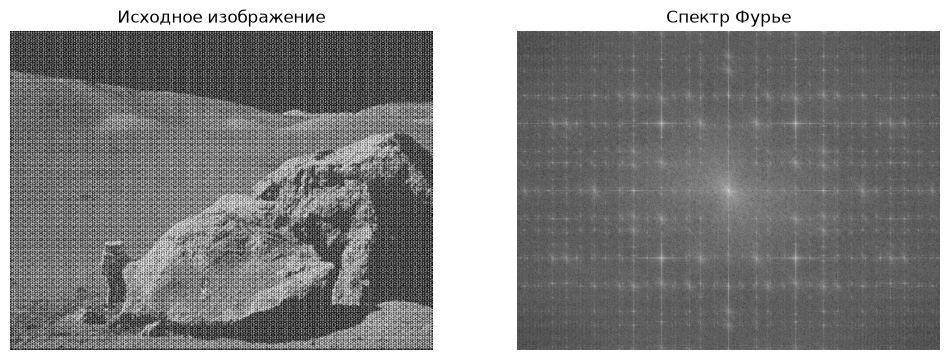

In [3]:
## Пункт 1. Загрузка изображения и построение спектра Фурье

img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)

dft = cv.dft(
    np.float32(img),
    flags=cv.DFT_COMPLEX_OUTPUT
)

dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(
    cv.magnitude(
        dft_shift[:, :, 0],
        dft_shift[:, :, 1]
    ) + 1
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Спектр Фурье')
plt.axis('off')

plt.show()

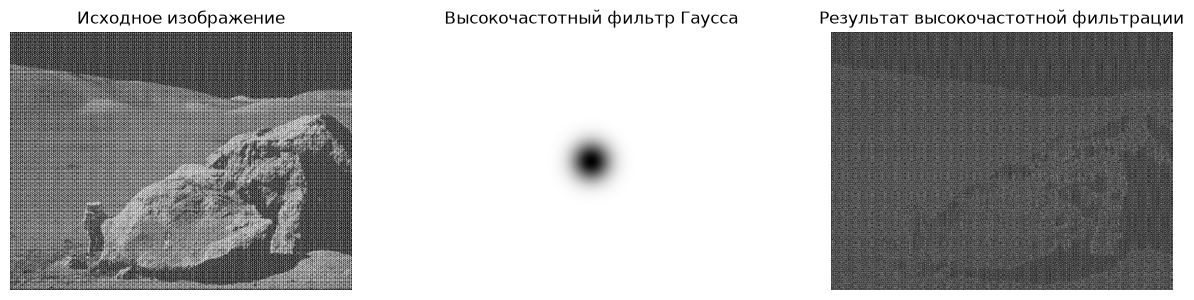

In [7]:
## Пункт 2. Высокочастотная фильтрация на основе ядра Гаусса

rows, cols = img.shape

crow = rows // 2
ccol = cols // 2

sigma = 30

x = np.arange(cols)
y = np.arange(rows)

X, Y = np.meshgrid(x, y)

gaussian_low = np.exp(
    -((X - ccol)**  2 + (Y - crow)**  2) /
    (2 * sigma ** 2)
)

gaussian_high = 1 - gaussian_low

mask = np.zeros((rows, cols, 2), dtype=np.float32)
mask[:, :, 0] = gaussian_high
mask[:, :, 1] = gaussian_high

filtered_shift = dft_shift * mask

filtered_dft = np.fft.ifftshift(filtered_shift)

img_high = cv.idft(filtered_dft)

img_high = cv.magnitude(
    img_high[:, :, 0],
    img_high[:, :, 1]
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gaussian_high, cmap='gray')
plt.title('Высокочастотный фильтр Гаусса')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_high, cmap='gray')
plt.title('Результат высокочастотной фильтрации')
plt.axis('off')

plt.show()

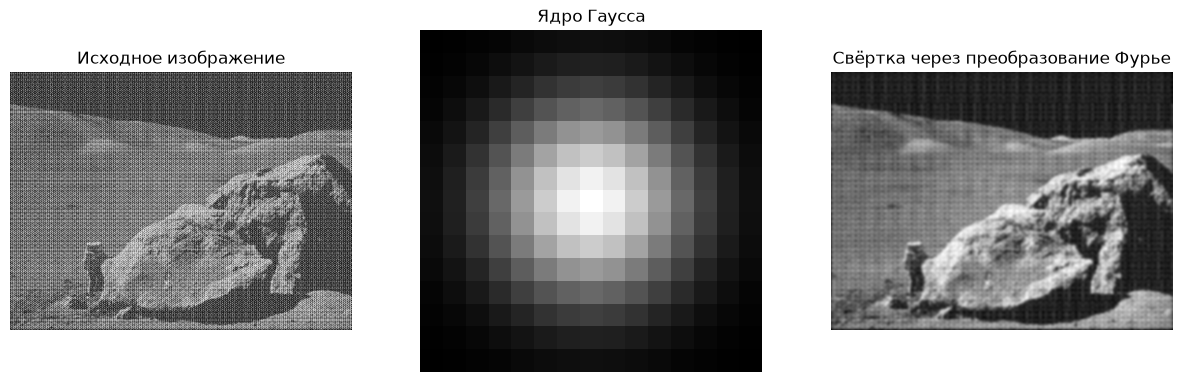

In [8]:
## Пункт 3. Вычисление свёртки с помощью преобразования Фурье

kernel_size = 15
sigma_conv = 3

gauss_1d = cv.getGaussianKernel(kernel_size, sigma_conv)
kernel = gauss_1d @ gauss_1d.T

rows, cols = img.shape
k_rows, k_cols = kernel.shape

kernel_padded = np.zeros((rows, cols), dtype=np.float32)

r0 = rows // 2 - k_rows // 2
c0 = cols // 2 - k_cols // 2

kernel_padded[
    r0:r0 + k_rows,
    c0:c0 + k_cols
] = kernel

kernel_padded = np.fft.ifftshift(kernel_padded)

img_fft = np.fft.fft2(np.float32(img))
kernel_fft = np.fft.fft2(kernel_padded)

result_fft = img_fft * kernel_fft

convolution_fft = np.fft.ifft2(result_fft)
convolution_fft = np.real(convolution_fft)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(kernel, cmap='gray')
plt.title('Ядро Гаусса')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(convolution_fft, cmap='gray')
plt.title('Свёртка через преобразование Фурье')
plt.axis('off')

plt.show()

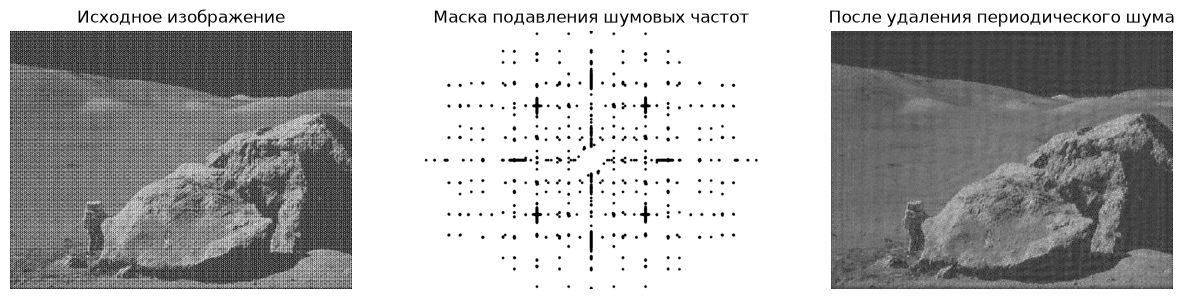

In [9]:
## Пункт 4. Удаление периодического шума с помощью преобразования Фурье

magnitude = cv.magnitude(
    dft_shift[:, :, 0],
    dft_shift[:, :, 1]
)

log_magnitude = np.log1p(magnitude)

rows, cols = img.shape
crow = rows // 2
ccol = cols // 2

mask_noise = np.ones((rows, cols), dtype=np.float32)

# Убираем центральную область из поиска шумовых пиков
search_spectrum = log_magnitude.copy()

cv.circle(
    search_spectrum,
    (ccol, crow),
    30,
    0,
    -1
)

# Выбираем наиболее яркие точки спектра
threshold_peak = np.percentile(search_spectrum, 99.7)

peak_points = np.argwhere(search_spectrum > threshold_peak)

# Подавляем найденные пики
for y, x in peak_points:
    cv.circle(
        mask_noise,
        (x, y),
        3,
        0,
        -1
    )

mask_noise_2ch = cv.merge(
    [mask_noise, mask_noise]
)

filtered_noise_shift = dft_shift * mask_noise_2ch

filtered_noise = np.fft.ifftshift(filtered_noise_shift)

img_denoised = cv.idft(filtered_noise)

img_denoised = cv.magnitude(
    img_denoised[:, :, 0],
    img_denoised[:, :, 1]
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_noise, cmap='gray')
plt.title('Маска подавления шумовых частот')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_denoised, cmap='gray')
plt.title('После удаления периодического шума')
plt.axis('off')

plt.show()

In [10]:
## Пункт 5. Итог

print('Итог работы:')
print('1. Реализована высокочастотная фильтрация на основе фильтра Гаусса.')
print('2. Реализовано вычисление свёртки с помощью преобразования Фурье.')
print('3. В спектре изображения обнаружены периодические шумовые частоты.')
print('4. Периодический шум был подавлен в частотной области.')
print('5. После обратного преобразования Фурье периодический шум на изображении значительно уменьшился.')

Итог работы:
1. Реализована высокочастотная фильтрация на основе фильтра Гаусса.
2. Реализовано вычисление свёртки с помощью преобразования Фурье.
3. В спектре изображения обнаружены периодические шумовые частоты.
4. Периодический шум был подавлен в частотной области.
5. После обратного преобразования Фурье периодический шум на изображении значительно уменьшился.
